# 0. RT-DETRv2 license plate detection error analysis

**Takeaway.** The baseline misses are concentrated among small plates, and the saved higher-resolution full-frame run trades a few small-plate recoveries for more misses elsewhere.

This analysis compares validation predictions from the epoch-19 EMA checkpoint. It covers detection, including the effect of input size, and uses the same annotated plates for each verified run. The opening cells load the artifacts and compute the TL;DR. Section 1 documents the inputs and settings.

In [20]:
%matplotlib inline

import csv
import hashlib
import json
import os
import random
import subprocess
import sys
from collections import Counter, defaultdict
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from matplotlib.ticker import PercentFormatter
from PIL import Image, ImageDraw
from scipy.stats import binomtest

SEED = 19
random.seed(SEED)
np.random.seed(SEED)
SCORE = 0.50
IOU = 0.50
TOP_K = 300
FP_BUDGET = 57
MIN_SOURCE_HEIGHT = 10
REPORT_EDGES = [0, 16, 30, 40, 60, np.inf]
REPORT_BINS = ["≤16", "(16, 30]", "(30, 40]", "(40, 60]", ">60"]
DETAIL_EDGES = [0, 8, 12, 16, 20, 25, 30, 40, 60, np.inf]
DETAIL_BINS = ["≤8", "(8, 12]", "(12, 16]", "(16, 20]", "(20, 25]",
               "(25, 30]", "(30, 40]", "(40, 60]", ">60"]
COLORS = {"640": "#325F91", "960": "#C45138", "Train": "#527C63"}
MATCHER_COMMIT = "77f1cf3b7f2548f715ca9c0ea92255dba5ae217f"

ROOT = Path(os.environ.get("ERROR_ANALYSIS_ROOT", Path.cwd())).resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
RUNS = ROOT / "runs/baseline-001/eval-epoch19"
ARTIFACTS = {
    "Validation annotations": ROOT / "data/raw/annotations/kaggle_val_annotations.json",
    "Training annotations": ROOT / "data/baseline_v1_0/annotations.json",
    "640 predictions": RUNS / "fresh-evaluation/predictions.json",
    "640 manifest": RUNS / "fresh-evaluation/prediction-manifest.json",
    "960 predictions": RUNS / "resolution-960/predictions.json",
    "Saved baseline matches": RUNS / "error-analysis/matches.csv",
    "Saved baseline summary": RUNS / "error-analysis/summary.json",
    "Resolved training config": ROOT / "docs/reports/baseline-001/resolved-training-config.json",
}
CHECKPOINT = ROOT / "runs/baseline-001/checkpoints/checkpoint0019.pth"
IMAGE_DIR = ROOT / "data/raw/valid"


def read_json(path):
    with path.open(encoding="utf-8") as source:
        return json.load(source)


def sha256(path):
    with path.open("rb") as source:
        return hashlib.file_digest(source, "sha256").hexdigest()


artifact_hashes = {label: sha256(path) for label, path in ARTIFACTS.items()}
manifest = read_json(ARTIFACTS["640 manifest"])
training_config = read_json(ARTIFACTS["Resolved training config"])["yaml_cfg"]
assert training_config["eval_spatial_size"] == [640, 640]
assert artifact_hashes["960 predictions"] == (
    "510189f9fb77928d33b01c33f42effa8af583f18c6342f7a395556c2265c2e50"
), "960 export differs from the reviewed file"
provenance = manifest["provenance"]
assert manifest["predictions"]["sha256"] == artifact_hashes["640 predictions"]
assert provenance["annotations"]["sha256"] == artifact_hashes["Validation annotations"]
assert provenance["weight_selection"] == "ema.module"
assert provenance["inference"]["num_top_queries"] == TOP_K
assert provenance["inference"]["confidence_cutoff"] is None
assert not provenance["inference"]["nms_applied"]
if CHECKPOINT.is_file():
    assert sha256(CHECKPOINT) == provenance["checkpoint"]["sha256"]

# Load the exact repository matcher used for the baseline. The working-copy
# matcher may be configured for the MVP and use a strict score threshold.
matcher_path = f"{MATCHER_COMMIT}:scripts/eval_match.py"
matcher_source = subprocess.check_output(
    ["git", "-C", str(ROOT), "show", matcher_path], text=True
)
matcher = {"__name__": "baseline_matcher", "__file__": str(ROOT / "scripts/eval_match.py")}
exec(compile(matcher_source, matcher_path, "exec"), matcher)
assert (matcher["SCORE_THRESH"], matcher["IOU_THRESH"]) == (SCORE, IOU)
matcher["self_test"]()

In [21]:
def plate_table(coco):
    images = {item["id"]: item for item in coco["images"]}
    assert len(images) == len(coco["images"])
    table = pd.DataFrame(coco["annotations"]).rename(columns={"id": "annotation_id"})
    assert table["annotation_id"].is_unique
    table = table.set_index("annotation_id")
    table[["x", "y", "source_width", "source_height"]] = pd.DataFrame(
        table["bbox"].tolist(), index=table.index
    )
    image_width = table["image_id"].map({key: value["width"] for key, value in images.items()})
    assert image_width.gt(0).all()
    assert table[["source_width", "source_height"]].gt(0).all().all()
    table["width_640"] = 640 * table["source_width"] / image_width
    table["width_bin"] = pd.cut(table["width_640"], REPORT_EDGES, labels=REPORT_BINS)
    return images, table


eval_images, plates = plate_table(read_json(ARTIFACTS["Validation annotations"]))
_, train_plates = plate_table(read_json(ARTIFACTS["Training annotations"]))
assert (len(eval_images), len(plates), len(train_plates)) == (2048, 2195, 10_000)
assert Counter(item["image_id"] for item in manifest["processed_images"]) == dict.fromkeys(eval_images, 1)
assert all(item["prediction_count"] == TOP_K for item in manifest["processed_images"])
assert manifest["processed_image_count"] == len(eval_images)
assert manifest["prediction_count"] == len(eval_images) * TOP_K

gt_by_image = defaultdict(list)
annotation_ids = {}
for annotation_id, plate in plates.iterrows():
    gt_by_image[plate.image_id].append(plate.bbox)
    key = (plate.image_id, *plate.bbox)
    assert key not in annotation_ids, f"Ambiguous annotation identity: {key}"
    annotation_ids[key] = annotation_id

In [22]:
BOX_FIELDS = ["x", "y", "w", "h"]
GT_FIELDS = [f"gt_{field}" for field in BOX_FIELDS]
PRED_FIELDS = [f"pred_{field}" for field in BOX_FIELDS]


def evaluate_export(path):
    """Use the baseline matcher for both the fixed threshold and the score sweep."""
    by_image = defaultdict(list)
    for pred in read_json(path):
        box = pred["bbox"]
        assert len(box) == 4 and all(np.isfinite(box)) and min(box[2:]) > 0
        assert 0 <= pred["score"] <= 1
        by_image[pred["image_id"]].append(pred)
    assert {key: len(value) for key, value in by_image.items()} == dict.fromkeys(eval_images, TOP_K)

    at_score = []
    ranked_detections = []
    match_image = matcher["match_image"]
    for image_id, image in eval_images.items():
        truth, predictions = gt_by_image[image_id], by_image[image_id]
        at_score.extend(match_image(image, truth, predictions))

        # Greedy assignments only depend on earlier (higher-scored) detections.
        # Match all candidates once to recover every inclusive threshold prefix.
        matcher["SCORE_THRESH"] = 0.0
        try:
            ranked_detections.extend(
                (row["score"], row["type"] == "TP")
                for row in match_image(image, truth, predictions)
                if row["type"] in ("TP", "FP")
            )
        finally:
            matcher["SCORE_THRESH"] = SCORE

    hit_boxes = {}
    for row in at_score:
        if row["type"] == "TP":
            key = (row["image_id"], *(row[field] for field in GT_FIELDS))
            hit_boxes[annotation_ids[key]] = tuple(row[field] for field in PRED_FIELDS)

    scores = pd.DataFrame(ranked_detections, columns=["Threshold", "hit"])
    assert len(scores) == len(eval_images) * TOP_K
    by_score = scores.groupby("Threshold")["hit"].agg(["sum", "size"]).sort_index(ascending=False)
    tp = by_score["sum"].cumsum()
    fp = (by_score["size"] - by_score["sum"]).cumsum()
    curve = pd.DataFrame({"TP": tp, "FP": fp, "Precision": tp / (tp + fp), "Recall": tp / len(plates)})
    counts = Counter(row["type"] for row in at_score)
    assert len(hit_boxes) == counts["TP"] and counts["TP"] + counts["FN"] == len(plates)
    at_operating_point = curve.loc[curve.index >= SCORE].iloc[-1]
    assert (at_operating_point["TP"], at_operating_point["FP"]) == (counts["TP"], counts["FP"])
    return at_score, hit_boxes, curve


runs = {
    size: evaluate_export(ARTIFACTS[f"{size} predictions"])
    for size in ("640", "960")
}

# Match every historical CSV row, including FP/FN subtypes, not just the totals.
with ARTIFACTS["Saved baseline matches"].open(encoding="utf-8", newline="") as source:
    reader = csv.DictReader(source)
    fields = reader.fieldnames
    saved_rows = Counter(tuple(row[key] for key in fields) for row in reader)
assert Counter(tuple(str(row[key]) for key in fields) for row in runs["640"][0]) == saved_rows

records = []
for size, (rows, boxes, _) in runs.items():
    totals = Counter(row["type"] for row in rows)
    tp, fp, fn = (totals[key] for key in ("TP", "FP", "FN"))
    records.append({
        "Run": size, "TP": tp, "FP": fp, "FN": fn,
        "Precision": tp / (tp + fp), "Recall": tp / (tp + fn),
    })
    plates[f"hit_{size}"] = plates.index.isin(boxes)
metrics = pd.DataFrame(records).set_index("Run")
saved_summary = read_json(ARTIFACTS["Saved baseline summary"])
for field in ("TP", "FP", "FN", "precision", "recall"):
    col = field if field.isupper() else field.capitalize()
    assert metrics.loc["640", col] == saved_summary[field], f"Baseline summary mismatch: {field}"
expected_metrics = {
    "640": (2019, 57, 176, "97.25%", "91.98%"),
    "960": (1981, 129, 214, "93.89%", "90.25%"),
}
for size, row in metrics.iterrows():
    measured = (row.TP, row.FP, row.FN, f"{row.Precision:.2%}", f"{row.Recall:.2%}")
    assert measured == expected_metrics[size], f"{size}: measured {measured}"

baseline = metrics.loc["640"]
small = plates.loc[plates["width_640"].le(16)]
cutoff = plates.loc[plates["source_height"].ge(MIN_SOURCE_HEIGHT)]
display(Markdown(
    "### TL;DR\n"
    f"- **Baseline:** {int(baseline.TP):,} true positives, {int(baseline.FP)} false positives, "
    f"and {int(baseline.FN)} misses. Precision is {baseline.Precision:.2%} and recall is {baseline.Recall:.2%}.\n"
    f"- **Small plates:** {int((~small.hit_640).sum())}/{len(small)} plates ≤16 effective px are missed. "
    f"{int(small.source_height.lt(MIN_SOURCE_HEIGHT).sum())} are under {MIN_SOURCE_HEIGHT} source px tall.\n"
    f"- **First action:** report the full set alongside the proposed {MIN_SOURCE_HEIGHT} px cutoff. "
    f"Filtering the existing matches gives {cutoff.hit_640.mean():.2%} recall. "
    "Verify the ignore-region FP count and audit training labels before fine-tuning."
))

### TL;DR
- **Baseline:** 2,019 true positives, 57 false positives, and 176 misses. Precision is 97.25% and recall is 91.98%.
- **Small plates:** 55/55 plates ≤16 effective px are missed. 36 are under 10 source px tall.
- **First action:** report the full set alongside the proposed 10 px cutoff. Filtering the existing matches gives 94.75% recall. Verify the ignore-region FP count and audit training labels before fine-tuning.

## 1. Setup

**Takeaway.** All comparisons use the same validation annotations, 640-based width bins, and the baseline matching rule.

The model sees a direct square resize. Effective plate width is calculated as **640 × source plate width ÷ source image width**. Source width and height use the COCO box dimensions in original pixels. Tiling used a separate historical full-frame-plus-tile merge. Its underlying detections are unavailable.

In [23]:
display(Markdown(
    f"- **Checkpoint:** epoch-19 EMA, `{CHECKPOINT.relative_to(ROOT)}`\n"
    f"- **Data:** {len(eval_images):,} validation images, {len(plates):,} eval plates, "
    f"{len(train_plates):,} training annotations\n"
    f"- **Operating point:** confidence ≥ {SCORE:.2f}, IoU ≥ {IOU:.2f}, "
    f"one-to-one greedy matching, top-{TOP_K}, full-frame exports without NMS\n"
    "- **Available:** 640 and 960 predictions. **PENDING:** original 800 and tiling artifacts."
))

- **Checkpoint:** epoch-19 EMA, `runs/baseline-001/checkpoints/checkpoint0019.pth`
- **Data:** 2,048 validation images, 2,195 eval plates, 10,000 training annotations
- **Operating point:** confidence ≥ 0.50, IoU ≥ 0.50, one-to-one greedy matching, top-300, full-frame exports without NMS
- **Available:** 640 and 960 predictions. **PENDING:** original 800 and tiling artifacts.

## 2. Baseline performance

**Takeaway.** The full-set operating point has high precision, with the remaining misses examined by plate size below.

The precision–recall curve sweeps the saved top-300 candidates at IoU ≥0.50. Each score threshold includes all detections with that score. The dot marks the fixed confidence 0.50 operating point.

**Table 1. 640 baseline at confidence ≥0.50.**

,TP,FP,FN,Precision,Recall
Run,,,,,
640,2019,57,176,97.25%,91.98%


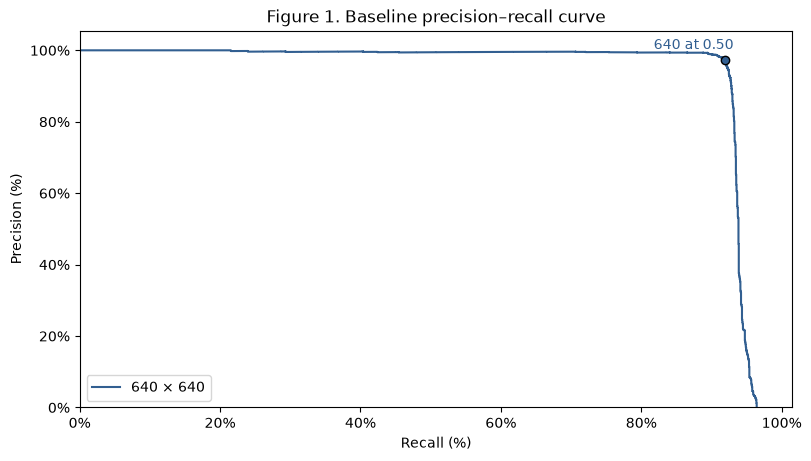

In [24]:
percent_columns = {"Precision": "{:.2%}", "Recall": "{:.2%}"}
display(Markdown("**Table 1. 640 baseline at confidence ≥0.50.**"))
display(metrics.loc[["640"]].style.format(percent_columns))


def plot_pr(sizes, title):
    fig, ax = plt.subplots(figsize=(8, 4.5), layout="constrained")
    for size in sizes:
        curve = runs[size][2]
        row = metrics.loc[size]
        ax.step(curve["Recall"], curve["Precision"], where="post", color=COLORS[size], label=f"{size} × {size}")
        ax.scatter(row["Recall"], row["Precision"], color=COLORS[size], edgecolor="black", zorder=3)
        ax.annotate(
            f"{size} at 0.50", (row["Recall"], row["Precision"]),
            xytext=(6, 8 if size == "640" else -17), textcoords="offset points",
            ha="right" if size == "640" else "left", color=COLORS[size],
        )
    ax.set(xlabel="Recall (%)", ylabel="Precision (%)", title=title,
           xlim=(0, 1.015), ylim=(0, 1.055))
    for axis in (ax.xaxis, ax.yaxis):
        axis.set_major_formatter(PercentFormatter(1))
    ax.legend(loc="lower left")
    plt.show()


plot_pr(["640"], "Figure 1. Baseline precision–recall curve")

## 3. Error slicing

**Takeaway.** Miss rates rise in the small-width bins, and many of the tiniest plates are only a few pixels tall in the original images.

Width bins are fixed at the 640 input scale. Wilson intervals describe uncertainty in each bin-level miss rate. The train/eval comparison uses annotation dimensions before training augmentation.

**Table 2. Baseline misses by effective width.**

,Plates,Missed,Miss rate,Wilson low,Wilson high
Width at 640 (px),,,,,
≤16,55,55,100.00%,93.47%,100.00%
"(16, 30]",80,54,67.50%,56.64%,76.76%
"(30, 40]",42,17,40.48%,27.04%,55.51%
"(40, 60]",193,16,8.29%,5.17%,13.04%
>60,1825,34,1.86%,1.34%,2.59%


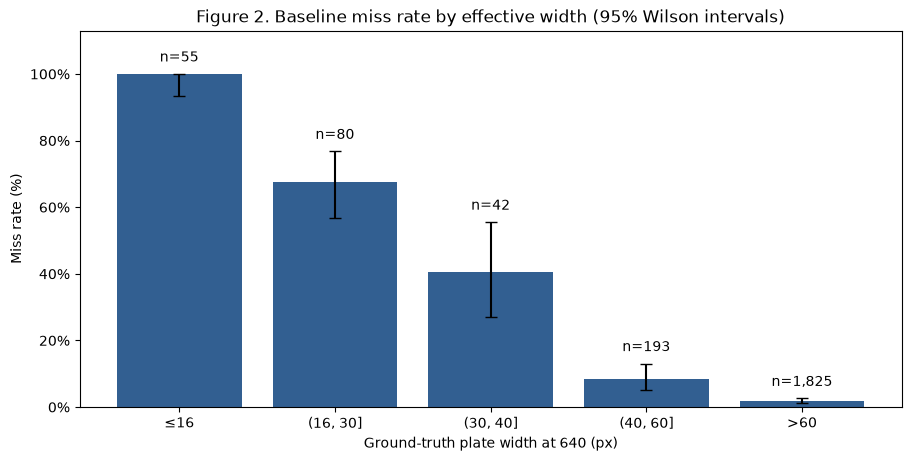

In [25]:
def miss_rates(table, bins):
    grouped = table.groupby(bins, observed=False)["hit_640"]
    n = grouped.size()
    missed = n - grouped.sum()
    rate = missed / n
    z = 1.959963984540054
    denominator = 1 + z**2 / n
    center = (rate + z**2 / (2 * n)) / denominator
    margin = z * np.sqrt(rate * (1 - rate) / n + z**2 / (4 * n**2)) / denominator
    return pd.DataFrame({
        "Plates": n, "Missed": missed, "Miss rate": rate,
        "Wilson low": (center - margin).clip(0, 1), "Wilson high": (center + margin).clip(0, 1),
    }).rename_axis("Width at 640 (px)")


rate_formats = {key: "{:.2%}" for key in ("Miss rate", "Wilson low", "Wilson high")}
width_slice = miss_rates(plates, plates["width_bin"])
assert width_slice["Plates"].sum() == len(plates)
assert width_slice["Missed"].sum() == baseline.FN
assert width_slice.loc["(30, 40]", "Plates"] == 42
wide_misses = int((plates["width_640"].gt(40) & ~plates["hit_640"]).sum())
assert wide_misses == 50, f"Observed {wide_misses} misses above 40 effective px"

display(Markdown("**Table 2. Baseline misses by effective width.**"))
display(width_slice.style.format(rate_formats))

fig, ax = plt.subplots(figsize=(9, 4.5), layout="constrained")
yerr = [
    (width_slice["Miss rate"] - width_slice["Wilson low"]).clip(lower=0),
    (width_slice["Wilson high"] - width_slice["Miss rate"]).clip(lower=0),
]
ax.bar(width_slice.index, width_slice["Miss rate"], yerr=yerr, capsize=4, color=COLORS["640"])
for index, row in enumerate(width_slice.itertuples(index=False, name=None)):
    ax.annotate(f"n={int(row[0]):,}", (index, row[4]), xytext=(0, 9),
                textcoords="offset points", ha="center")
ax.set(title="Figure 2. Baseline miss rate by effective width (95% Wilson intervals)",
       xlabel="Ground-truth plate width at 640 (px)", ylabel="Miss rate (%)", ylim=(0, 1.13))
ax.set_yticks(np.linspace(0, 1, 6))
ax.yaxis.set_major_formatter(PercentFormatter(1))
plt.show()

**Source dimensions for the 55 plates ≤16 effective px.** Source height is below 10 px for 36 plates. Median height is 7.34 px and minimum height is 1.60 px.

,source_width,source_height
min,3.3,1.60
median,13.5,7.34
max,45.5,28.33


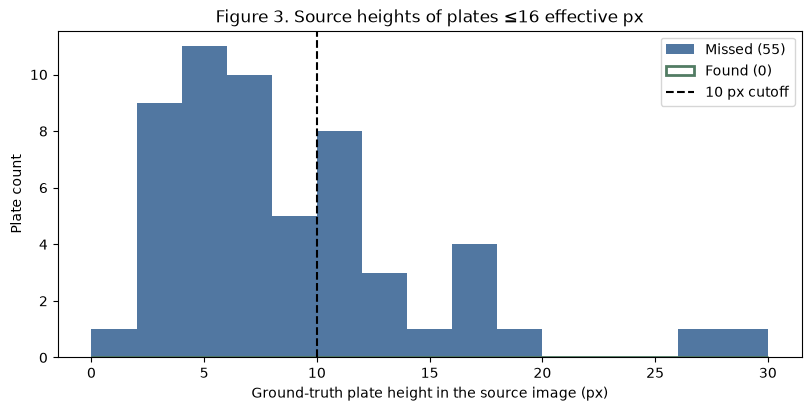

**Table 3. Source height cutoff at the baseline operating point.** Recall uses existing assignments at confidence 0.50. An ignore-region FP count is PENDING.

,Plates,Found,Missed,Recall
Cohort,,,,
Full validation set,2195,2019,176,91.98%
Source height <10 px (excluded),82,17,65,20.73%
Source height ≥10 px (retained),2113,2002,111,94.75%


In [26]:
below_cutoff = plates.loc[plates["source_height"].lt(MIN_SOURCE_HEIGHT)]
small_below = int(small["source_height"].lt(MIN_SOURCE_HEIGHT).sum())
small_min = small["source_height"].min()
small_median = small["source_height"].median()
observed_small = (len(small), small_below, int(small.hit_640.sum()), f"{small_median:.2f}", f"{small_min:.2f}")
assert observed_small == (55, 36, 0, "7.34", "1.60"), f"Observed ≤16 px cohort: {observed_small}"

source_cohorts = {
    "Full validation set": plates,
    "Source height <10 px (excluded)": below_cutoff,
    "Source height ≥10 px (retained)": cutoff,
}
source_counts = pd.DataFrame([
    {"Cohort": label, "Plates": len(group), "Found": int(group.hit_640.sum()),
     "Missed": int((~group.hit_640).sum()), "Recall": group.hit_640.mean()}
    for label, group in source_cohorts.items()
]).set_index("Cohort")
observed_cutoff = (len(below_cutoff), int(below_cutoff.hit_640.sum()), int((~below_cutoff.hit_640).sum()),
                   int(cutoff.hit_640.sum()), len(cutoff), f"{cutoff.hit_640.mean():.2%}")
assert observed_cutoff == (82, 17, 65, 2002, 2113, "94.75%"), f"Observed cutoff: {observed_cutoff}"

display(Markdown(
    f"**Source dimensions for the {len(small)} plates ≤16 effective px.** "
    f"Source height is below {MIN_SOURCE_HEIGHT} px for {small_below} plates. "
    f"Median height is {small_median:.2f} px and minimum height is {small_min:.2f} px."
))
display(small[["source_width", "source_height"]].agg(["min", "median", "max"]).round(2))
height_edges = np.arange(0, small.source_height.max() + 2, 2)
fig, ax = plt.subplots(figsize=(8, 4), layout="constrained")
missed_heights = small.loc[~small.hit_640, "source_height"]
found_heights = small.loc[small.hit_640, "source_height"]
ax.hist(missed_heights, bins=height_edges, color=COLORS["640"], alpha=0.85,
        label=f"Missed ({len(missed_heights)})")
ax.hist(found_heights, bins=height_edges, histtype="step", linewidth=2,
        color=COLORS["Train"], label=f"Found ({len(found_heights)})")
ax.axvline(MIN_SOURCE_HEIGHT, color="black", linestyle="--",
           label=f"{MIN_SOURCE_HEIGHT} px cutoff")
ax.set(title="Figure 3. Source heights of plates ≤16 effective px",
       xlabel="Ground-truth plate height in the source image (px)", ylabel="Plate count")
ax.legend()
plt.show()
display(Markdown(
    "**Table 3. Source height cutoff at the baseline operating point.** "
    "Recall uses existing assignments at confidence 0.50. An ignore-region FP count is PENDING."
))
display(source_counts.style.format({"Recall": "{:.2%}"}))

**Table 4. Train and eval plate counts on the report bins.**

,Train,Eval
Width at 640 (px),,
≤16,0,55
"(16, 30]",1,80
"(30, 40]",11,42
"(40, 60]",374,193
>60,9614,1825


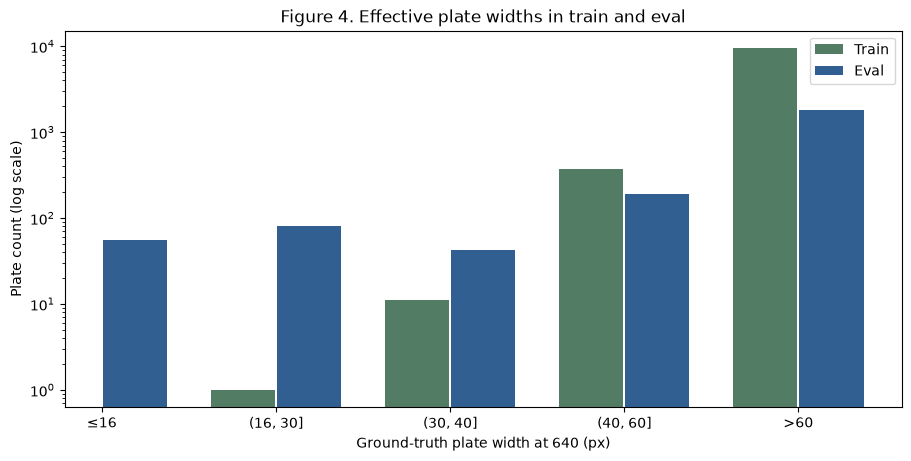

In [27]:
width_counts = pd.DataFrame({
    "Train": train_plates["width_bin"].value_counts(sort=False),
    "Eval": plates["width_bin"].value_counts(sort=False),
}).rename_axis("Width at 640 (px)")
assert tuple(width_counts.sum()) == (len(train_plates), len(plates))
under_40 = width_counts.iloc[:3].sum()
observed_widths = (tuple(width_counts["Train"].iloc[:3]), tuple(width_counts["Eval"].iloc[:3]))
assert observed_widths == ((0, 1, 11), (55, 80, 42)), f"Observed widths through 40 px: {observed_widths}"
assert tuple(under_40) == (12, 177)
display(Markdown("**Table 4. Train and eval plate counts on the report bins.**"))
display(width_counts)

fig, ax = plt.subplots(figsize=(9, 4.5), layout="constrained")
x = np.arange(len(REPORT_BINS))
for cohort, offset, color in (("Train", -0.19, COLORS["Train"]), ("Eval", 0.19, COLORS["640"])):
    counts = width_counts[cohort]
    valid = counts.gt(0).to_numpy()
    ax.bar(x[valid] + offset, counts[valid], width=0.37, color=color, label=cohort)
ax.set(title="Figure 4. Effective plate widths in train and eval",
       xlabel="Ground-truth plate width at 640 (px)", ylabel="Plate count (log scale)",
       yscale="log", xticks=x, xticklabels=REPORT_BINS)
ax.legend()
plt.show()

## 4. Inference experiments

**Takeaway.** At 960, the checkpoint recovers some baseline misses, loses more plates overall, and has lower recall at the same false-positive budget.

Fixed-confidence comparisons use confidence ≥0.50. For the matched comparison, choose the score threshold with maximum recall among all thresholds with at most 57 false positives. For ties in recall, choose the point closest to 57 FPs, then the highest threshold. Full-frame candidates are capped at 300 per image.

In [28]:
RUN_LABELS = {"640": "640 baseline", "800": "800 full frame", "960": "960 full frame", "Tiling": "Tiling"}
# Transcribed from the historical experiments. Raw predictions are unavailable.
historical = pd.DataFrame.from_dict({
    "800": {"TP": 2006, "FP": 87, "FN": 189},
    "Tiling": {"TP": 2040, "FP": 504, "FN": 155},
}, orient="index")
historical["Precision"] = historical.TP / (historical.TP + historical.FP)
historical["Recall"] = historical.TP / (historical.TP + historical.FN)
comparison = pd.concat([
    metrics.assign(Evidence="Verified from saved export"),
    historical.assign(Evidence="Historically reported; verification PENDING"),
]).reindex(RUN_LABELS).rename(index=RUN_LABELS)
display(Markdown("**Table 5. Inference experiments at the recorded operating point.**"))
display(comparison.style.format(percent_columns))

matched = []
for size, (_, _, curve) in runs.items():
    within_budget = curve.loc[curve["FP"].le(FP_BUDGET)]
    best_recall = within_budget.loc[within_budget["TP"].eq(within_budget["TP"].max())]
    threshold = best_recall["FP"].idxmax()
    point = within_budget.loc[threshold]
    matched.append({"Run": size, "Threshold": threshold, "TP": int(point.TP),
                    "FP": int(point.FP), "Recall": point.Recall})
matched = pd.DataFrame(matched).set_index("Run")
for size, expected in {"640": (2019, 57, "91.98%"), "960": (1959, 57, "89.25%")}.items():
    row = matched.loc[size]
    measured = (row.TP, row.FP, f"{row.Recall:.2%}")
    assert measured == expected, f"{size} at the FP budget: observed {measured}"

display(Markdown(
    f"**Table 6. Full-set recall at a budget of {FP_BUDGET} false positives.** "
    "Reported thresholds are rounded for display."
))
matched_report = matched.rename(index=RUN_LABELS).reindex(comparison.index).astype(object)
for column, fmt in {"Threshold": "{:.9f}", "TP": "{:,.0f}", "FP": "{:,.0f}", "Recall": "{:.2%}"}.items():
    matched_report[column] = matched_report[column].map(lambda value: fmt.format(value) if pd.notna(value) else "PENDING")
display(matched_report)

**Table 5. Inference experiments at the recorded operating point.**

,TP,FP,FN,Precision,Recall,Evidence
640 baseline,2019,57,176,97.25%,91.98%,Verified from saved export
800 full frame,2006,87,189,95.84%,91.39%,Historically reported; verification PENDING
960 full frame,1981,129,214,93.89%,90.25%,Verified from saved export
Tiling,2040,504,155,80.19%,92.94%,Historically reported; verification PENDING


**Table 6. Full-set recall at a budget of 57 false positives.** Reported thresholds are rounded for display.

,Threshold,TP,FP,Recall
640 baseline,0.508056521,"2,019",57,91.98%
800 full frame,PENDING,PENDING,PENDING,PENDING
960 full frame,0.679799974,"1,959",57,89.25%
Tiling,PENDING,PENDING,PENDING,PENDING


**Table 7. Paired outcomes versus 640.** Every row compares the same ground-truth annotations at confidence 0.50. Exact two-sided McNemar p-values use recovered and lost counts. Bin-level p-values are exploratory and unadjusted for multiple comparisons.

Recovered     Lost Both hit Both missed  \
Run            Width at 640 (px)                                           
800 full frame ≤16                 PENDING  PENDING  PENDING     PENDING   
               (16, 30]            PENDING  PENDING  PENDING     PENDING   
               (30, 40]            PENDING  PENDING  PENDING     PENDING   
               (40, 60]            PENDING  PENDING  PENDING     PENDING   
               >60                 PENDING  PENDING  PENDING     PENDING   
               All plates          PENDING  PENDING  PENDING     PENDING   
960 full frame ≤16                       0        0        0          55   
               (16, 30]                  4        2       24          50   
               (30, 40]                  3        2       23          14   
               (40, 60]                  4        4      173          12   
               >60                       7       48     1743          27   
               All plates               18       56     1963         158   
Tiling         ≤16                 PENDING  PENDING  PENDING     PENDING   
               (16, 30]            PENDING  PENDING  PENDING     PENDING   
               (30, 40]            PENDING  PENDING  PENDING     PENDING   
               (40, 60]            PENDING  PENDING  PENDING     PENDING   
               >60                 PENDING  PENDING  PENDING     PENDING   
               All plates          PENDING  PENDING  PENDING     PENDING   

                                   Net TP McNemar p  
Run            Width at 640 (px)                     
800 full frame ≤16                PENDING   PENDING  
               (16, 30]           PENDING   PENDING  
               (30, 40]           PENDING   PENDING  
               (40, 60]           PENDING   PENDING  
               >60                PENDING   PENDING  
               All plates         PENDING   PENDING  
960 full frame ≤16                      0         1  
               (16, 30]                 2     0.688  
               (30, 40]                 1         1  
               (40, 60]                 0         1  
               >60                    -41  1.31e-08  
               All plates             -38  1.11e-05  
Tiling         ≤16                PENDING   PENDING  
               (16, 30]           PENDING   PENDING  
               (30, 40]           PENDING   PENDING  
               (40, 60]           PENDING   PENDING  
               >60                PENDING   PENDING  
               All plates         PENDING   PENDING

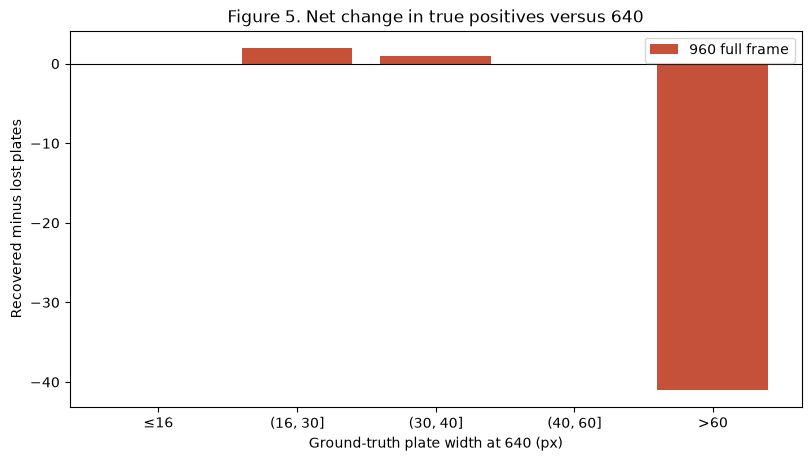

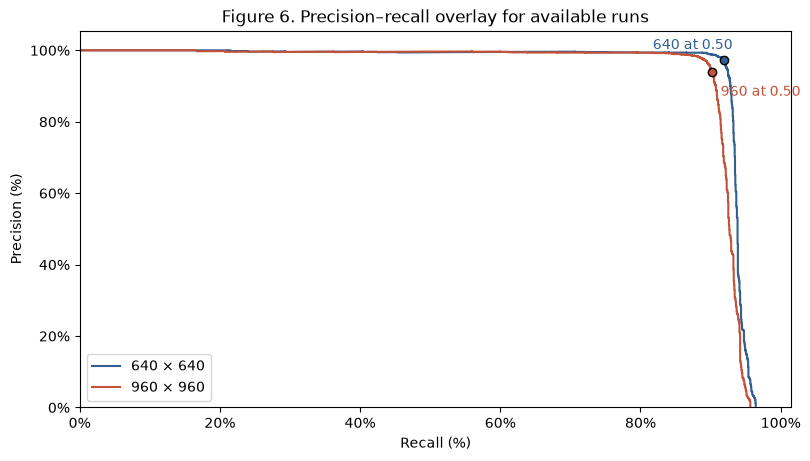

In [29]:
OUTCOMES = ["Recovered", "Lost", "Both hit", "Both missed"]
paired = {}
for size in runs:
    if size == "640":
        continue
    other = plates[f"hit_{size}"]
    status = pd.Categorical(
        np.select([~plates.hit_640 & other, plates.hit_640 & ~other, plates.hit_640 & other],
                  OUTCOMES[:3], default=OUTCOMES[3]),
        categories=OUTCOMES,
    )
    plates[f"status_{size}"] = status
    counts = pd.crosstab(plates["width_bin"], status, dropna=False)
    counts = counts.reindex(index=REPORT_BINS, columns=OUTCOMES, fill_value=0)
    assert counts.sum(axis=1).eq(width_slice["Plates"]).all()
    counts = pd.concat([counts, counts.sum().to_frame().T.rename(index={0: "All plates"})])
    counts["Net TP"] = counts["Recovered"] - counts["Lost"]
    assert counts.loc["All plates", "Net TP"] == metrics.loc[size, "TP"] - baseline.TP
    counts["McNemar p"] = [
        binomtest(recovered, recovered + lost, p=0.5).pvalue if recovered + lost else 1.0
        for recovered, lost in zip(counts["Recovered"], counts["Lost"])
    ]
    paired[size] = counts

expected_pairs = [(0, 0), (4, 2), (3, 2), (4, 4), (7, 48), (18, 56)]
observed_pairs = list(paired["960"][["Recovered", "Lost"]].itertuples(index=False, name=None))
assert observed_pairs == expected_pairs, f"Observed 960 pairs: {observed_pairs}"

pair_tables = {}
for size in ("800", "960", "Tiling"):
    if size in paired:
        pair_tables[RUN_LABELS[size]] = paired[size].copy()
        pair_tables[RUN_LABELS[size]]["McNemar p"] = paired[size]["McNemar p"].map("{:.3g}".format)
    else:
        pair_tables[RUN_LABELS[size]] = pd.DataFrame(
            "PENDING", index=[*REPORT_BINS, "All plates"], columns=[*OUTCOMES, "Net TP", "McNemar p"]
        )
paired_report = pd.concat(pair_tables, names=["Run", "Width at 640 (px)"])
display(Markdown(
    "**Table 7. Paired outcomes versus 640.** Every row compares the same ground-truth annotations "
    "at confidence 0.50. Exact two-sided McNemar p-values use recovered and lost counts. "
    "Bin-level p-values are exploratory and unadjusted for multiple comparisons."
))
display(paired_report)

fig, ax = plt.subplots(figsize=(8, 4.5), layout="constrained")
ax.bar(REPORT_BINS, paired["960"].loc[REPORT_BINS, "Net TP"], color=COLORS["960"], label="960 full frame")
ax.axhline(0, color="black", linewidth=0.8)
ax.set(title="Figure 5. Net change in true positives versus 640",
       xlabel="Ground-truth plate width at 640 (px)", ylabel="Recovered minus lost plates")
ax.legend()
plt.show()
plot_pr(["640", "960"], "Figure 6. Precision–recall overlay for available runs")

**PENDING — 800 and tiling comparisons.** Populate the paired table and net-TP bars only after recovering the original annotation-level evidence. PR curves and recall at the FP budget require scored candidates before the confidence cutoff and, for tiling, the original merge settings. The historical tiling result used a full 640 pass and overlapping 640 tiles. Tiling's merged totals alone do not establish improvement in every bin.

## 5. Failure modes and hypotheses

**Takeaway.** Small source dimensions and a gap in annotated training sizes are measured findings. The historical tiling result suggests some misses are recoverable.

In [30]:
tiling = historical.loc["Tiling"]
tiling_gain = int(tiling.TP - baseline.TP)
train_share_40 = under_40.Train / len(train_plates)
eval_share_40 = under_40.Eval / len(plates)
display(Markdown(f"""
| ID | Title | Status | Key evidence | Fix |
| --- | --- | --- | --- | --- |
| H1 | Information-limited plates | Confirmed for measured size and recall | {small_below}/{len(small)} plates ≤16 effective px are <10 source px tall (Figure 3). | Report full-set and cutoff-set recall. Audit tiny labels. |
| H2 | Training distribution gap | Confirmed for annotated sizes | ≤40 effective px: {int(under_40.Train)}/{len(train_plates):,} in train vs. {int(under_40.Eval)}/{len(plates):,} in eval (Table 4). | Check annotation coverage, then improve small-plate training data. |
| H3 | Downscaling to 640 discards recoverable pixels | Supported by the historical result | Tiling: +{tiling_gain} net TP, {int(tiling.FP)} FPs, {tiling.Precision:.2%} precision (Table 5, verification PENDING). | Improve the merge and compare at matched FPs. |

### H1. Information-limited plates

**Claim.** The smallest plates have few source pixels available and show high baseline miss rates.

- **Table 2** shows {width_slice.iloc[0]["Missed"]}/{len(small)} baseline misses in the ≤16 effective px bin.
- **Figure 3** shows {small_below}/{len(small)} below {MIN_SOURCE_HEIGHT} source px tall (median {small_median:.2f} px, minimum {small_min:.2f} px).
- **Table 3** excludes {len(below_cutoff)} annotations below {MIN_SOURCE_HEIGHT} px, including {int(below_cutoff.hit_640.sum())} found and {int((~below_cutoff.hit_640).sum())} missed. The retained set has {int(cutoff.hit_640.sum()):,}/{len(cutoff):,} plates found ({cutoff.hit_640.mean():.2%} vs. {baseline.Recall:.2%} on the full set).

**Status.** Confirmed for the observed sizes and baseline outcomes. The recoverability of individual tiny plates remains open.

**Proposed fix.** Report both cohorts, audit the smallest labels, and evaluate the proposed ignore rule separately.

**What would reject it.** Reliable recovery of these same tiny plates at a comparable false-positive rate would challenge the claim that their source resolution limits detection.

### H2. Training distribution gap

**Claim.** Small annotated plates are much rarer in the baseline training set than in validation at the same resize.

- **Figure 4 and Table 4** show {int(under_40.Train)}/{len(train_plates):,} training plates ({train_share_40:.2%}) and {int(under_40.Eval)}/{len(plates):,} eval plates ({eval_share_40:.2%}) at ≤40 effective px.
- **Table 4** shows {width_counts.iloc[0].Train} training plates at ≤16 px, {width_counts.iloc[1].Train} in (16, 30], and {width_counts.iloc[2].Train} in (30, 40]. The counts come directly from each annotation file.
- **Table 2** shows higher baseline miss rates in the smaller bins than above 40 px.

**Status.** Confirmed for annotated sizes. **PENDING:** determine whether visible small plates occur infrequently, lack labels, or both.

**Proposed fix.** Check approximately 20 training images for visible small plates and annotation coverage before changing the training mix.

**What would reject it.** A representative annotation audit that closes the observed size gap after accounting for missing labels would reject the interpretation that small plates are scarce in the underlying training images.

### H3. Downscaling to 640 discards recoverable pixels

**Claim.** Some plates missed after full-frame resizing can be recovered by processing native-resolution regions.

- **Table 5** records a historical tiling result of +{tiling_gain} net TP with {int(tiling.FP)} FPs and {tiling.Precision:.2%} precision.
- **Table 7 and Figure 5** show that 960 full-frame inference recovers {paired["960"].loc["All plates", "Recovered"]} plates and loses {paired["960"].loc["All plates", "Lost"]}. The effect depends on how images are presented to this checkpoint.
- **Table 6** shows the full-frame result at {FP_BUDGET} FPs. Tiling performance at that budget is **PENDING**.

**Status.** Supported by the historical tile experiment. **PENDING:** per-bin improvements and the causes of added FPs, including duplicates, tile-edge truncation, and unlabeled plates.

**Proposed fix.** Improve the tile merge and measure recall at the same FP budget before adopting it.

**What would reject it.** Reproducing the tiled run and finding zero additional correctly matched plates would undermine the recoverable-detail explanation.

**Not yet characterized.** The {wide_misses} baseline misses above 40 effective px still need review for blur, angle, occlusion, and label noise.
"""))


| ID | Title | Status | Key evidence | Fix |
| --- | --- | --- | --- | --- |
| H1 | Information-limited plates | Confirmed for measured size and recall | 36/55 plates ≤16 effective px are <10 source px tall (Figure 3). | Report full-set and cutoff-set recall. Audit tiny labels. |
| H2 | Training distribution gap | Confirmed for annotated sizes | ≤40 effective px: 12/10,000 in train vs. 177/2,195 in eval (Table 4). | Check annotation coverage, then improve small-plate training data. |
| H3 | Downscaling to 640 discards recoverable pixels | Supported by the historical result | Tiling: +21 net TP, 504 FPs, 80.19% precision (Table 5, verification PENDING). | Improve the merge and compare at matched FPs. |

### H1. Information-limited plates

**Claim.** The smallest plates have few source pixels available and show high baseline miss rates.

- **Table 2** shows 55.0/55 baseline misses in the ≤16 effective px bin.
- **Figure 3** shows 36/55 below 10 source px tall (median 7.34 px, minimum 1.60 px).
- **Table 3** excludes 82 annotations below 10 px, including 17 found and 65 missed. The retained set has 2,002/2,113 plates found (94.75% vs. 91.98% on the full set).

**Status.** Confirmed for the observed sizes and baseline outcomes. The recoverability of individual tiny plates remains open.

**Proposed fix.** Report both cohorts, audit the smallest labels, and evaluate the proposed ignore rule separately.

**What would reject it.** Reliable recovery of these same tiny plates at a comparable false-positive rate would challenge the claim that their source resolution limits detection.

### H2. Training distribution gap

**Claim.** Small annotated plates are much rarer in the baseline training set than in validation at the same resize.

- **Figure 4 and Table 4** show 12/10,000 training plates (0.12%) and 177/2,195 eval plates (8.06%) at ≤40 effective px.
- **Table 4** shows 0 training plates at ≤16 px, 1 in (16, 30], and 11 in (30, 40]. The counts come directly from each annotation file.
- **Table 2** shows higher baseline miss rates in the smaller bins than above 40 px.

**Status.** Confirmed for annotated sizes. **PENDING:** determine whether visible small plates occur infrequently, lack labels, or both.

**Proposed fix.** Check approximately 20 training images for visible small plates and annotation coverage before changing the training mix.

**What would reject it.** A representative annotation audit that closes the observed size gap after accounting for missing labels would reject the interpretation that small plates are scarce in the underlying training images.

### H3. Downscaling to 640 discards recoverable pixels

**Claim.** Some plates missed after full-frame resizing can be recovered by processing native-resolution regions.

- **Table 5** records a historical tiling result of +21 net TP with 504 FPs and 80.19% precision.
- **Table 7 and Figure 5** show that 960 full-frame inference recovers 18 plates and loses 56. The effect depends on how images are presented to this checkpoint.
- **Table 6** shows the full-frame result at 57 FPs. Tiling performance at that budget is **PENDING**.

**Status.** Supported by the historical tile experiment. **PENDING:** per-bin improvements and the causes of added FPs, including duplicates, tile-edge truncation, and unlabeled plates.

**Proposed fix.** Improve the tile merge and measure recall at the same FP budget before adopting it.

**What would reject it.** Reproducing the tiled run and finding zero additional correctly matched plates would undermine the recoverable-detail explanation.

**Not yet characterized.** The 50 baseline misses above 40 effective px still need review for blur, angle, occlusion, and label noise.


## 6. Ranked fixes and success criteria

**Takeaway.** Audit the labels and improve training coverage before adding a more complex inference pipeline.

1. **Eval policy.** Report both full-set and cutoff-set results. Match eligible plates first under the existing rule, then ignore otherwise-unmatched predictions overlapping a ground-truth plate below 10 source px at IoU ≥0.50. Audit labels below 5 px. Table 3 records the baseline cohort recall. The ignore-aware FP count and recall at that policy's FP budget are **PENDING**.
2. **Fine-tune with small-plate data.** Run the training-label audit first. Use plates at least 10 source px tall as small-plate targets. Oversample images with small plates, try zoom-out, mosaic and copy-paste, and check when augmentation turns off. Try multi-scale training (for example, 640–1120) and evaluate at 640 and 800–960.
3. **Tiling with a common merge.** On the fine-tuned model, test class-agnostic NMS across passes, rejection of detections touching interior tile edges, and a higher threshold for tile-only detections.
4. **Two-stage detection.** Detect vehicles and then plates within vehicle crops only if fine-tuning and tiling still fall short for eligible plates.

In [31]:
display(Markdown(
    f"**Primary.** Improve recall at the same budget of {FP_BUDGET} false positives. "
    f"The verified full-set baseline is {matched.loc['640', 'Recall']:.2%}. "
    f"The cutoff cohort baseline is {cutoff.hit_640.mean():.2%} at confidence {SCORE:.2f}. "
    "Measure its ignore-aware matched-FP baseline before scoring model changes.\n\n"
    "**Secondary.** Report recovered and lost counts by the fixed 640-based report bins with an exact "
    "two-sided McNemar test. Tiling passes only if it improves recall at the matched FP budget."
))

**Primary.** Improve recall at the same budget of 57 false positives. The verified full-set baseline is 91.98%. The cutoff cohort baseline is 94.75% at confidence 0.50. Measure its ignore-aware matched-FP baseline before scoring model changes.

**Secondary.** Report recovered and lost counts by the fixed 640-based report bins with an exact two-sided McNemar test. Tiling passes only if it improves recall at the matched FP budget.

## 7. Limitations and open items

**Takeaway.** This notebook supports the 640/960 and annotation comparisons. Additional evidence is needed to assess 800, tiling, and causes of individual errors.

- The 10 px source-height cutoff was chosen after seeing these predictions. Report full and retained cohorts together.
- Inference size changes use one checkpoint trained with a nominal 640 resize. Fine-tuning at higher resolutions could produce a different result.
- The (30, 40] px bin has 42 eval annotations. Use the Wilson interval in Table 2 when interpreting its miss rate.
- Training histograms use pre-augmentation annotations. Annotations bound the measured recall and precision, including whether detections of unlabeled plates count as false positives.
- A provenance manifest is available for 640. The 960 analysis verifies the saved boxes and their coverage.

| Status | Open item | Evidence needed |
| --- | --- | --- |
| PENDING | 800 metrics, paired outcomes, PR and matched FPs | Original scored 800 prediction export. |
| PENDING | Tiling metrics, per-bin improvements, PR and matched FPs | Original detections and merge settings, including candidates before the score cutoff for threshold sweeps. |
| PENDING | Cause of new tiling false positives | Review up to five new false positives for duplicates, truncated tile boxes, and unlabeled plates. |
| PENDING | Small-plate labeling versus rarity | Inspect approximately 20 relevant training images for visible plates and their annotations. |
| PENDING | Ignore-region policy and labels below 5 px | Audit tiny labels and evaluate both cohorts under the proposed policy. |
| PENDING | Baseline misses above 40 effective px | Review examples for blur, angle, occlusion, and label noise. |

## Appendix. Visual examples and reproducibility

**Takeaway.** Matched plates can be traced to an annotation ID and reviewed at both input sizes.

The green outline marks ground truth. The orange outline marks the prediction assigned to that annotation at confidence 0.50, when one exists. The panels show the directly resized inputs. Both columns are scaled by the notebook for display.

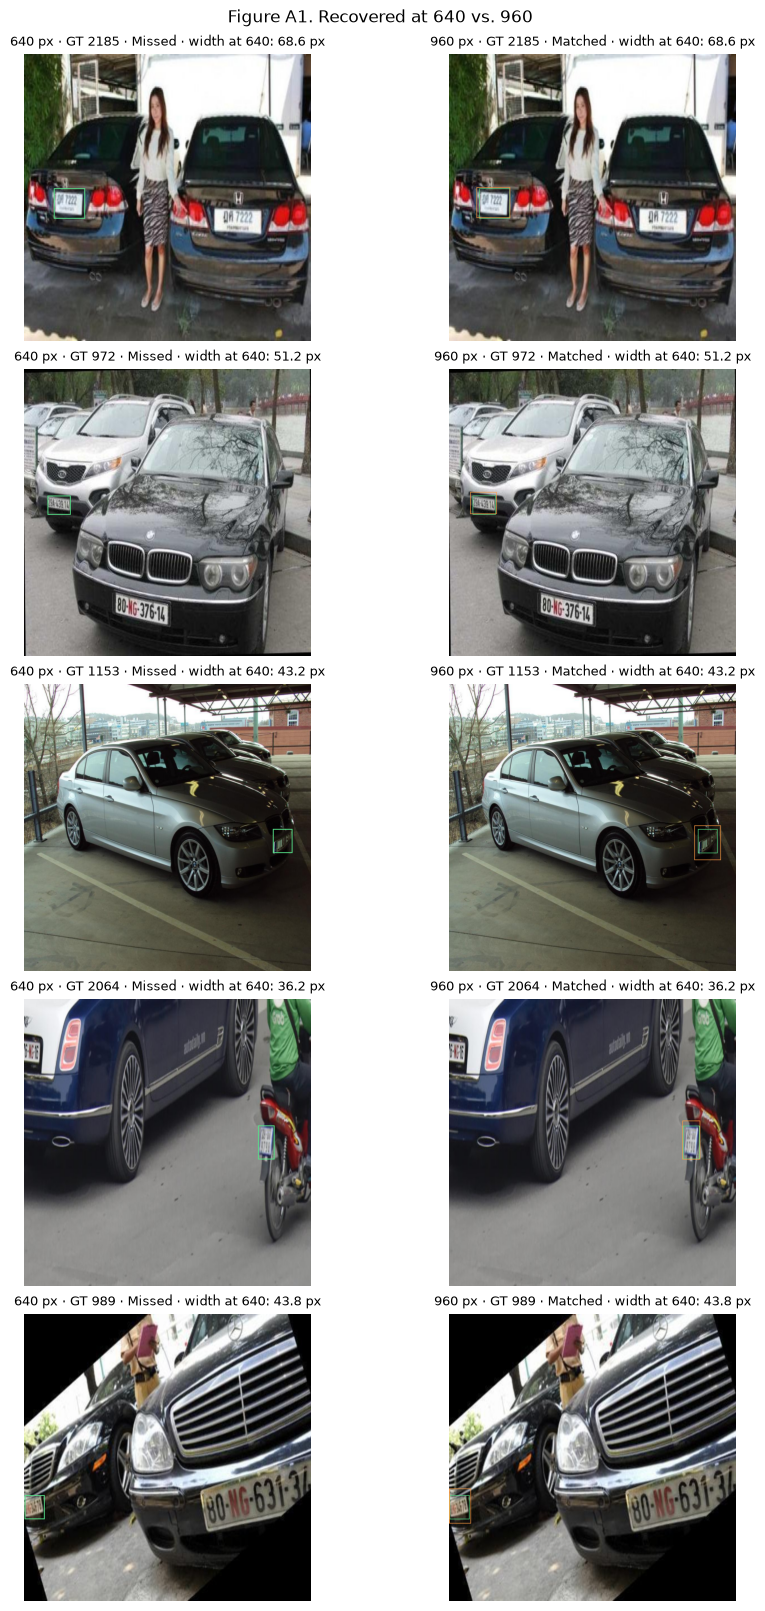

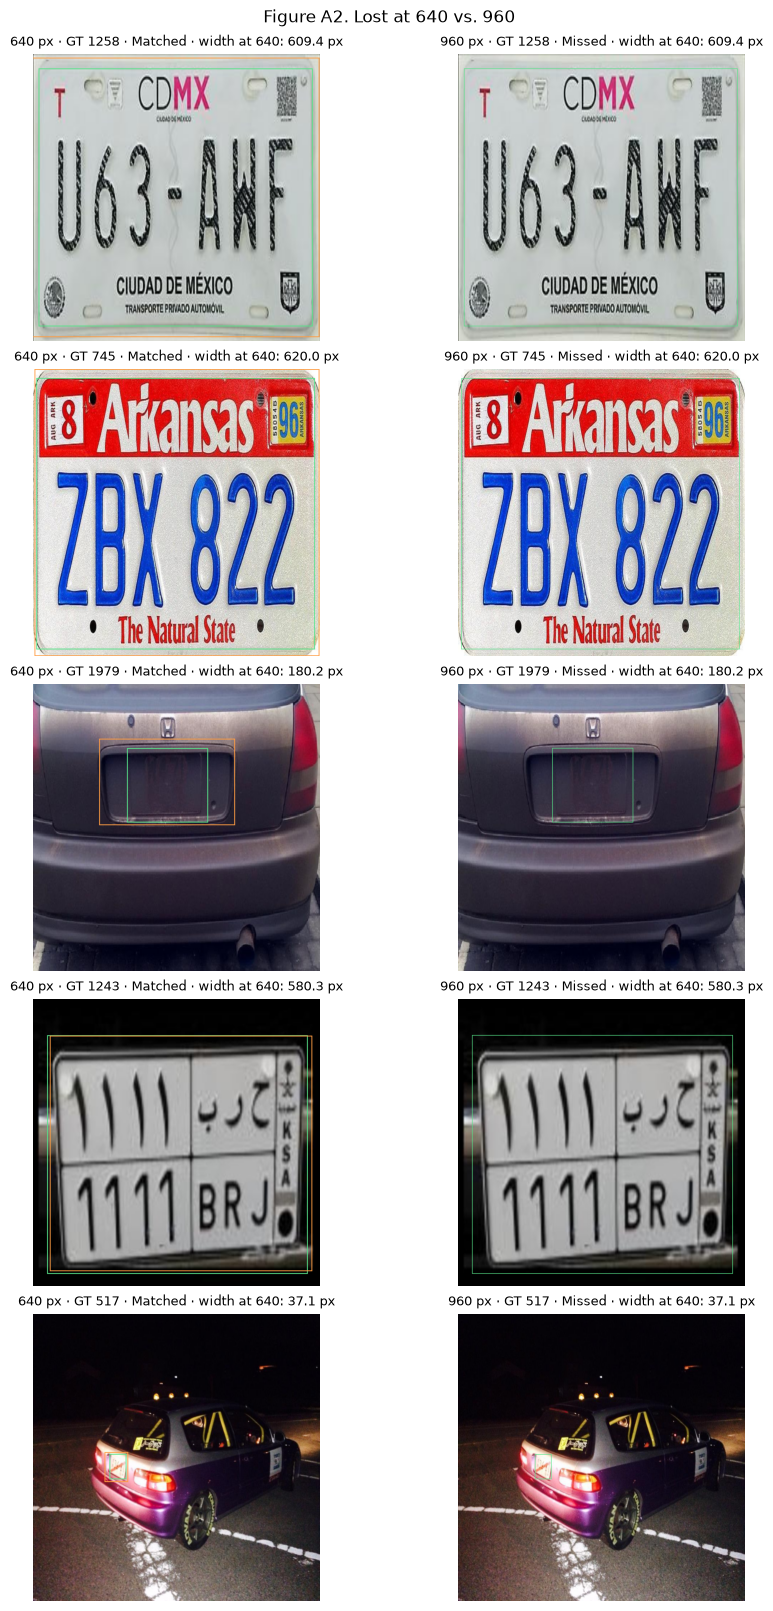

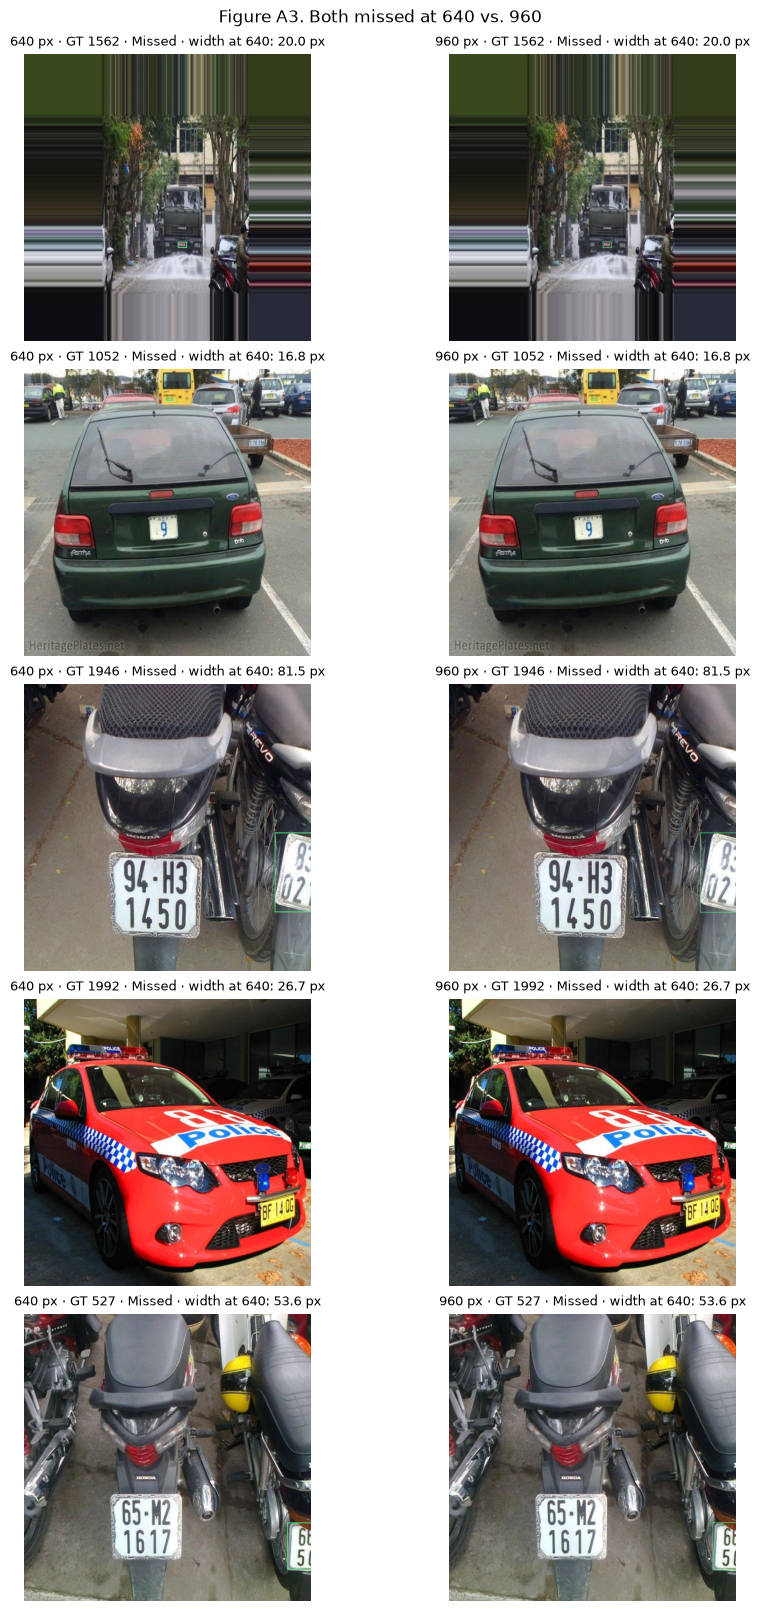

In [13]:
def resize_with_boxes(image, size, boxes):
    resized = image.resize((size, size), Image.Resampling.BILINEAR)
    sx, sy = size / image.width, size / image.height
    draw = ImageDraw.Draw(resized)
    for box, color in boxes:
        x, y, w, h = box
        draw.rectangle((x * sx, y * sy, (x + w) * sx, (y + h) * sy), outline=color, width=2)
    return resized


rng = np.random.default_rng(SEED)
for index, outcome in enumerate(("Recovered", "Lost", "Both missed"), start=1):
    pool = plates.index[plates["status_960"].eq(outcome)].sort_values()
    ids = rng.choice(pool.to_numpy(), size=min(5, len(pool)), replace=False)
    if len(ids) == 0:
        display(Markdown(f"**{outcome}.** No examples at confidence 0.50."))
        continue
    fig, axes = plt.subplots(len(ids), 2, figsize=(8.5, 3.2 * len(ids)), squeeze=False, layout="constrained")
    fig.suptitle(f"Figure A{index}. {outcome} at 640 vs. 960")
    for annotation_id, axes_row in zip(ids, axes):
        plate = plates.loc[annotation_id]
        path = IMAGE_DIR / Path(eval_images[plate.image_id]["file_name"]).name
        try:
            with Image.open(path) as original:
                image = original.convert("RGB")
        except OSError:
            image = None
        for size, ax in zip(("640", "960"), axes_row):
            prediction = runs[size][1].get(annotation_id)
            overlay = [(plate.bbox, "#57E389")]
            if prediction is not None:
                overlay.append((prediction, "#FF9D43"))
            label = "Matched" if prediction is not None else "Missed"
            if image is None:
                ax.text(0.5, 0.5, "PENDING — validation image unavailable", ha="center")
            else:
                ax.imshow(resize_with_boxes(image, int(size), overlay))
            ax.set_title(f"{size} px · GT {annotation_id} · {label} · width at 640: {plate.width_640:.1f} px",
                         fontsize=9)
            ax.axis("off")
    plt.show()

In [14]:
original_bins = pd.cut(plates["width_640"], DETAIL_EDGES, labels=DETAIL_BINS)
detail = miss_rates(plates, original_bins)
assert detail["Plates"].sum() == len(plates)
assert detail["Missed"].sum() == baseline.FN
display(Markdown("**Table A1. Original nine-bin breakdown for the 640 baseline.**"))
display(detail.style.format(rate_formats))

**Table A1. Original nine-bin breakdown for the 640 baseline.**

,Plates,Missed,Miss rate,Wilson low,Wilson high
Width at 640 (px),,,,,
≤8,10,10,100.00%,72.25%,100.00%
"(8, 12]",25,25,100.00%,86.68%,100.00%
"(12, 16]",20,20,100.00%,83.89%,100.00%
"(16, 20]",30,26,86.67%,70.32%,94.69%
"(20, 25]",26,18,69.23%,50.01%,83.50%
"(25, 30]",24,10,41.67%,24.47%,61.17%
"(30, 40]",42,17,40.48%,27.04%,55.51%
"(40, 60]",193,16,8.29%,5.17%,13.04%
>60,1825,34,1.86%,1.34%,2.59%


In [15]:
display(Markdown(
    "**Reproducibility.** Start from a clean kernel using the repository's Python environment. "
    "Run the notebook from the repository root or its notebooks directory. "
    "For an isolated notebook copy, set `ERROR_ANALYSIS_ROOT` to the original repository path. "
    "Execution reads local artifacts and uses the pinned baseline matcher from Git history. "
    "No new predictions are generated.\n\n"
    f"- Python {sys.version.split()[0]}, pandas {pd.__version__}, NumPy {np.__version__}\n"
    f"- Seed {SEED}; matcher revision `{MATCHER_COMMIT}`\n"
    f"- Scored export settings for 640: CPU, float32, batch size "
    f"{provenance['inference']['batch_size']}; PNG figures are rendered in the notebook.\n"
    "- Image-content hashes are unavailable. Visual examples use the local validation images."
))
identity = [
    {"Input": label, "File": str(path.relative_to(ROOT)), "SHA-256": artifact_hashes[label]}
    for label, path in ARTIFACTS.items()
]
identity.append({
    "Input": "Baseline checkpoint (manifest)", "File": str(CHECKPOINT.relative_to(ROOT)),
    "SHA-256": provenance["checkpoint"]["sha256"],
})
display(pd.DataFrame(identity).set_index("Input"))

**Reproducibility.** Start from a clean kernel using the repository's Python environment. Run the notebook from the repository root or its notebooks directory. For an isolated notebook copy, set `ERROR_ANALYSIS_ROOT` to the original repository path. Execution reads local artifacts and uses the pinned baseline matcher from Git history. No new predictions are generated.

- Python 3.12.9, pandas 3.1.0, NumPy 2.5.3
- Seed 19; matcher revision `77f1cf3b7f2548f715ca9c0ea92255dba5ae217f`
- Scored export settings for 640: CPU, float32, batch size 4; PNG figures are rendered in the notebook.
- Image-content hashes are unavailable. Visual examples use the local validation images.

,File,SHA-256
Input,,
Validation annotations,data/raw/annotations/kaggle_val_annotations.json,fc3b9de67de3b999ddb6ae66e86eec3ff12ed4e2763de9...
Training annotations,data/baseline_v1_0/annotations.json,abe7e6447eb7c6fd8cf1cdca5232a64363e963409807ff...
640 predictions,runs/baseline-001/eval-epoch19/fresh-evaluatio...,c1fdee17a4285ad027b323eb45bd925b5741d1c4232a83...
640 manifest,runs/baseline-001/eval-epoch19/fresh-evaluatio...,5ab84f8b88a0d18b5b00cc4d62170f05863f634f3832c7...
960 predictions,runs/baseline-001/eval-epoch19/resolution-960/...,510189f9fb77928d33b01c33f42effa8af583f18c6342f...
Saved baseline matches,runs/baseline-001/eval-epoch19/error-analysis/...,ba9bf7f558a47401cdb42a978a0e8d5d32c67fdeb1e1bc...
Saved baseline summary,runs/baseline-001/eval-epoch19/error-analysis/...,53ef7509291d71fdb1e82c2074d359e6d56e62cc7baacb...
Resolved training config,docs/reports/baseline-001/resolved-training-co...,b57c3a33249edb4e5fdfd828fb78383c7b4a4574e3706e...
Baseline checkpoint (manifest),runs/baseline-001/checkpoints/checkpoint0019.pth,a48b7e760bc273ed8ba52a6f749b0944d2e420e2393d71...
